**import dependcies**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
pd.set_option('display.max_columns', None)
sns.set_theme(rc = {"figure.figsize":(8,8)},font_scale=1.3)

**reading data**

In [ ]:
df = pd.read_csv("/UdemyCoursesDataset.csv", encoding = "latin-1")

In [ ]:
df.head()

,course_id,course_title,is_paid,price,num_subscribers,num_reviews,num_lectures,level,content_duration,published_timestamp,subject
0,288942,#1 Piano Hand Coordination: Play 10th Ballad i...,True,35,3137,18,68,All Levels,1.5 hours,2014-09-18T05:07:05Z,Musical Instruments
1,1170074,#10 Hand Coordination - Transfer Chord Ballad ...,True,75,1593,1,41,Intermediate Level,1 hour,2017-04-12T19:06:34Z,Musical Instruments
2,1193886,#12 Hand Coordination: Let your Hands dance wi...,True,75,482,1,47,Intermediate Level,1.5 hours,2017-04-26T18:34:57Z,Musical Instruments
3,1116700,#4 Piano Hand Coordination: Fun Piano Runs in ...,True,75,850,3,43,Intermediate Level,1 hour,2017-02-21T23:48:18Z,Musical Instruments
4,1120410,#5 Piano Hand Coordination: Piano Runs in 2 ...,True,75,940,3,32,Intermediate Level,37 mins,2017-02-21T23:44:49Z,Musical Instruments


In [ ]:
df.shape

(3676, 11)

In [ ]:
df.describe()

,course_id,num_subscribers,num_reviews,num_lectures
count,3.682000e+03,3682.000000,3682.000000,3682.000000
mean,6.766121e+05,3194.230310,156.093156,40.065182
std,3.436355e+05,9499.378361,934.957204,50.373299
min,8.324000e+03,0.000000,0.000000,0.000000
25%,4.078430e+05,110.250000,4.000000,15.000000
50%,6.885580e+05,911.500000,18.000000,25.000000
75%,9.617515e+05,2540.250000,67.000000,45.000000
max,1.282064e+06,268923.000000,27445.000000,779.000000


In [ ]:
df.describe(include="object")

,course_title,price,level,content_duration,published_timestamp,subject
count,3682,3682,3682,3682,3682,3682
unique,3667,38,4,109,3676,4
top,Acoustic Blues Guitar Lessons,20,All Levels,1 hour,2016-05-16T18:28:30Z,Web Development
freq,3,830,1932,607,2,1200


In [ ]:
df.isnull().sum().sort_values(ascending = False)

,0
course_id,0
course_title,0
is_paid,0
price,0
num_subscribers,0
num_reviews,0
num_lectures,0
level,0
content_duration,0
published_timestamp,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3682 entries, 0 to 3681
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   course_id            3682 non-null   int64 
 1   course_title         3682 non-null   object
 2   is_paid              3682 non-null   bool  
 3   price                3682 non-null   object
 4   num_subscribers      3682 non-null   int64 
 5   num_reviews          3682 non-null   int64 
 6   num_lectures         3682 non-null   int64 
 7   level                3682 non-null   object
 8   content_duration     3682 non-null   object
 9   published_timestamp  3682 non-null   object
 10  subject              3682 non-null   object
dtypes: bool(1), int64(4), object(6)
memory usage: 291.4+ KB


**check duplicate**

In [ ]:
df.duplicated().sum()

np.int64(6)

In [ ]:
df.drop_duplicates(inplace=True)
df.duplicated().sum()

np.int64(0)

**Edit the price column**



In [ ]:
df["price"].unique()

array(['35', '75', '65', '200', '25', '100', '20', '40', '30', '45',
       '185', '120', '105', '50', '0', '145', '55', '85', '110', '150',
       '95', '180', '125', '60', '90', '195', '80', '70', '140', '190',
       '115', '130', '170', '175', '165', '135', '155', '160'],
      dtype=object)

In [ ]:
df["price"] = df["price"].replace("Free","0")

In [ ]:
df["price"].unique()

array(['35', '75', '65', '200', '25', '100', '20', '40', '30', '45',
       '185', '120', '105', '50', '0', '145', '55', '85', '110', '150',
       '95', '180', '125', '60', '90', '195', '80', '70', '140', '190',
       '115', '130', '170', '175', '165', '135', '155', '160'],
      dtype=object)

In [32]:
df["price"] = pd.to_numeric(df["price"])

In [33]:
df["price"].dtype

dtype('int64')

**Edit the published_timestamp**

In [ ]:
df["published_timestamp"] = pd.to_datetime(df["published_timestamp"])
df['published_timestamp'].dtype

datetime64[ns, UTC]

In [89]:
df["year"] = df["published_timestamp"].dt.year
df["month"] = df["published_timestamp"].dt.month


KeyError: 'published_timestamp'

In [87]:
df["month"] = pd.to_datetime(df["month"],format="%m").dt.month_name()

In [ ]:
df.shape

(3676, 13)

In [ ]:
df.drop(["published_timestamp","course_id"], axis=1, inplace=True)

In [ ]:
df.shape

(3676, 11)

**data analysis**

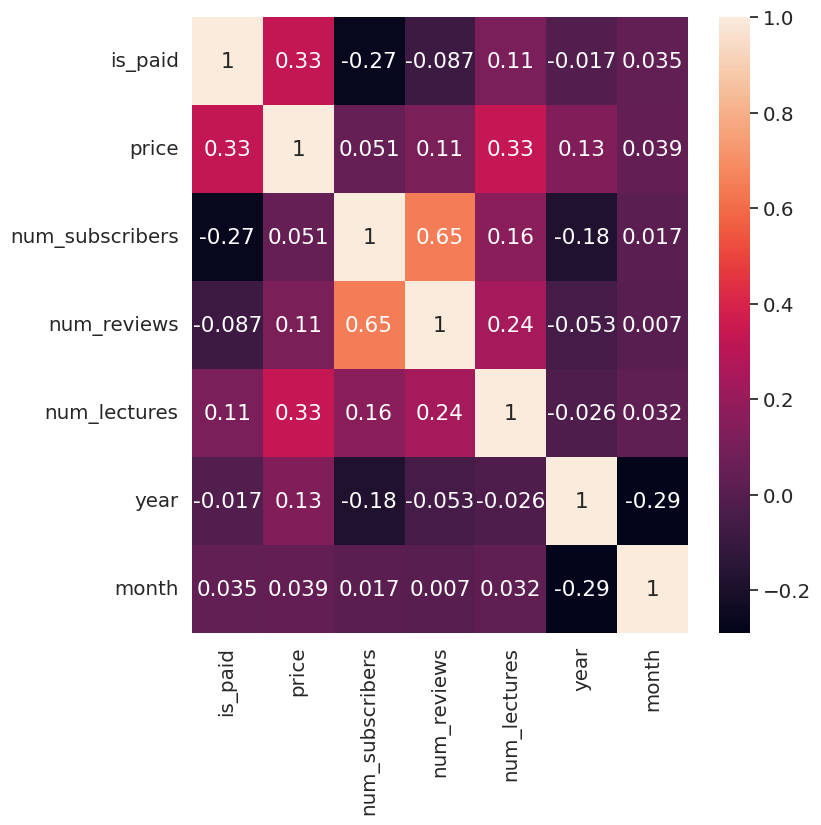

In [34]:
numerical_cols = df.select_dtypes(exclude=np.object_)
numerical_cols.head()
sns.heatmap(numerical_cols.corr(), annot=True)
plt.show()

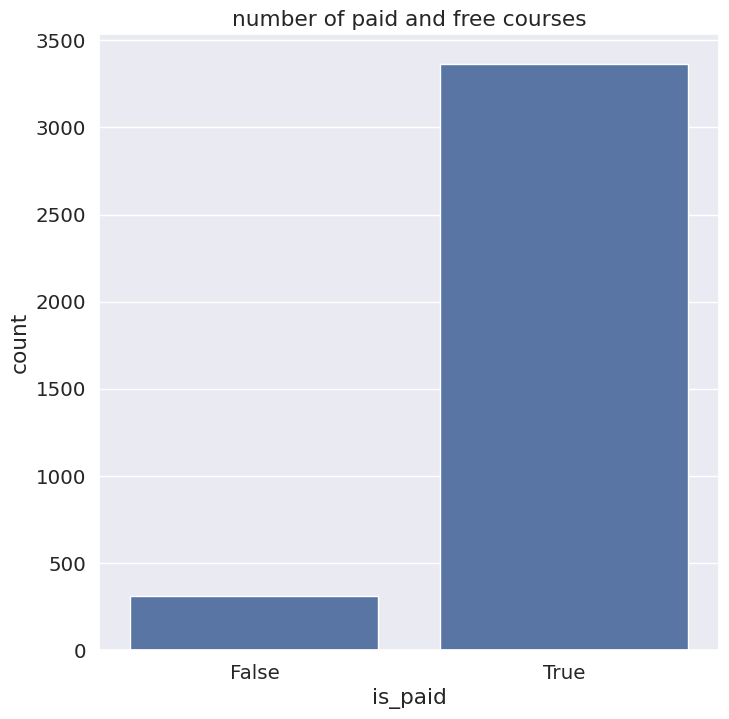

In [36]:
sns.countplot(data=df, x="is_paid")
plt.title("number of paid and free courses")
plt.show()

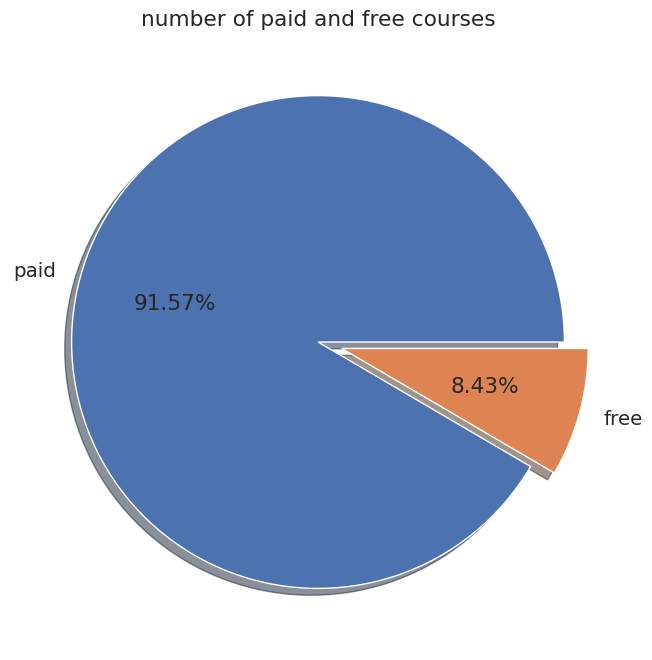

In [42]:
plt.pie(df["is_paid"].value_counts(), labels=["paid","free"], autopct="%.2f%%",shadow = "True",explode=(0,0.1))
plt.title("number of paid and free courses")
plt.show()

/tmp/ipykernel_932/2264088032.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="subject",palette="coolwarm")


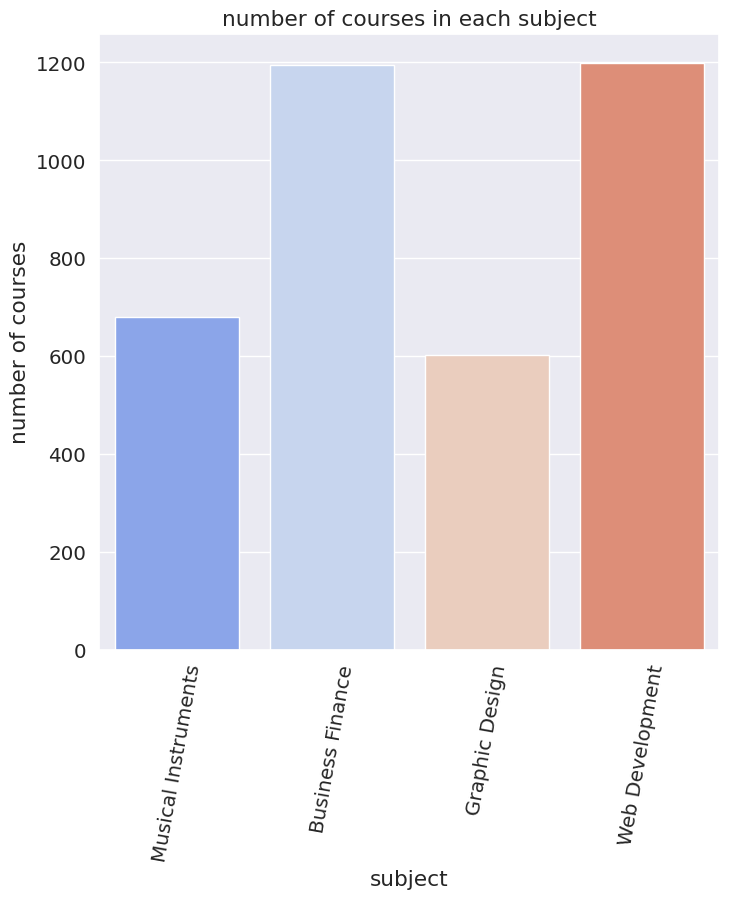

<Figure size 2000x800 with 0 Axes>

In [73]:
sns.countplot(data=df, x="subject",palette="coolwarm")
plt.title("number of courses in each subject")
plt.xlabel("subject")
plt.ylabel("number of courses")
plt.xticks(rotation = 80)
plt.figure(figsize=(20,8))
plt.show()

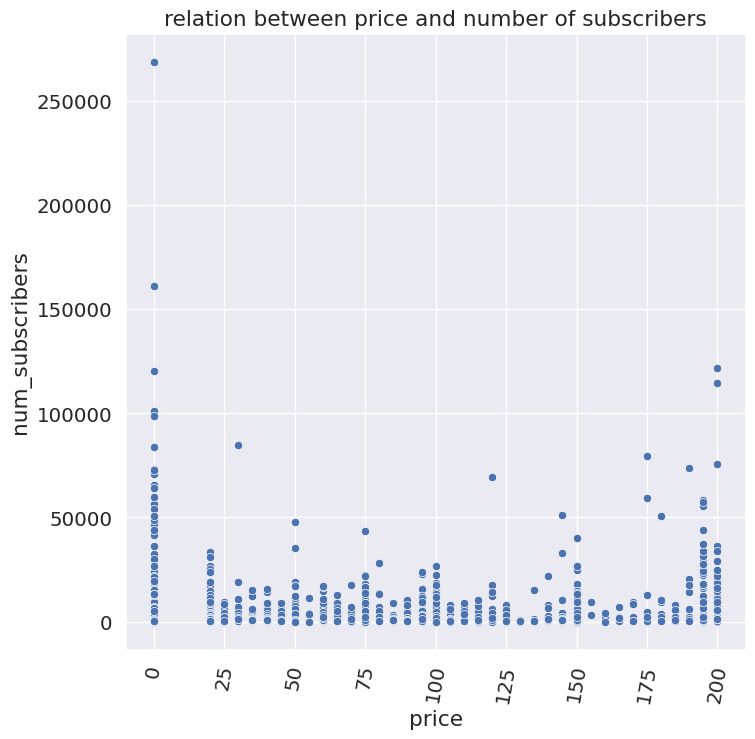

<Figure size 3000x800 with 0 Axes>

In [ ]:
sns.scatterplot(data = df ,x ="price",y="num_subscribers")
plt.title("relation between price and number of subscribers")
plt.xticks(rotation = 80)
plt.figure(figsize=(30,8))
plt.show()

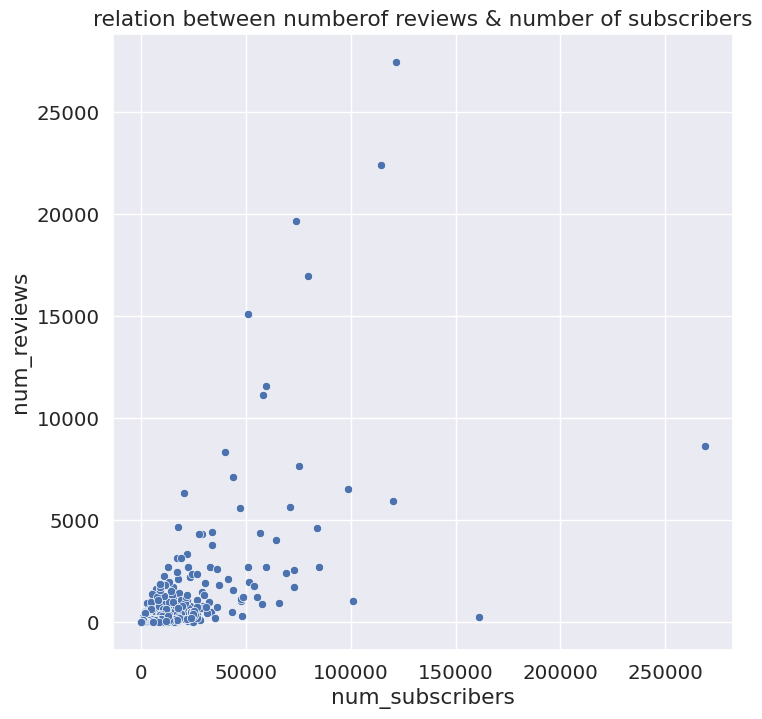

In [ ]:
sns.scatterplot(data=df, x='num_subscribers', y='num_reviews')
plt.title("relation between numberof reviews & number of subscribers")
plt.show()

In [ ]:
df["num_reviews"].corr(df['num_subscribers'])

np.float64(0.6510821953205432)

/tmp/ipykernel_932/3849968294.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='is_paid', y='num_subscribers',errorbar=None ,palette="Set2")


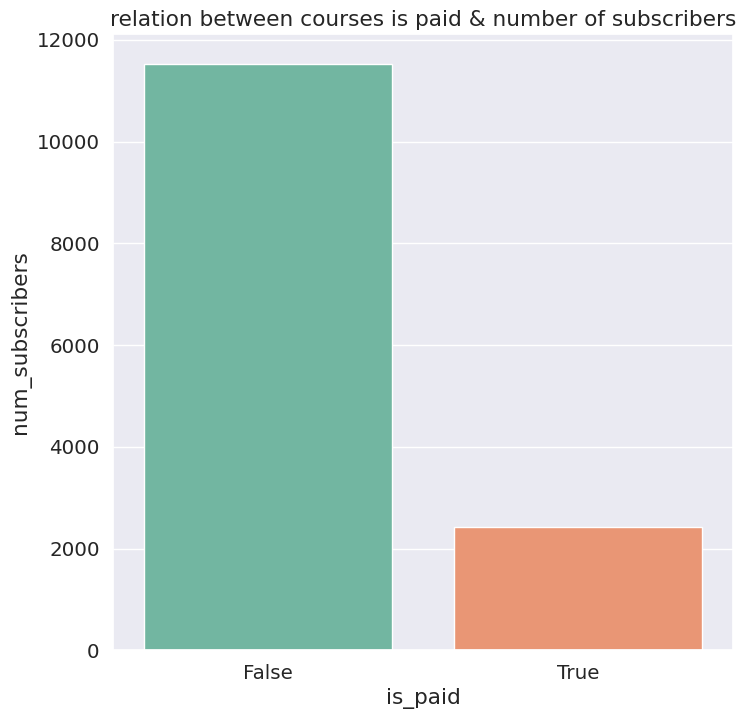

In [57]:
from IPython.core import error
sns.barplot(data=df, x='is_paid', y='num_subscribers',errorbar=None ,palette="Set2")
plt.title("relation between courses is paid & number of subscribers")
plt.show()

/tmp/ipykernel_932/1796032448.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='subject', y='num_subscribers',errorbar=None,palette="pastel")


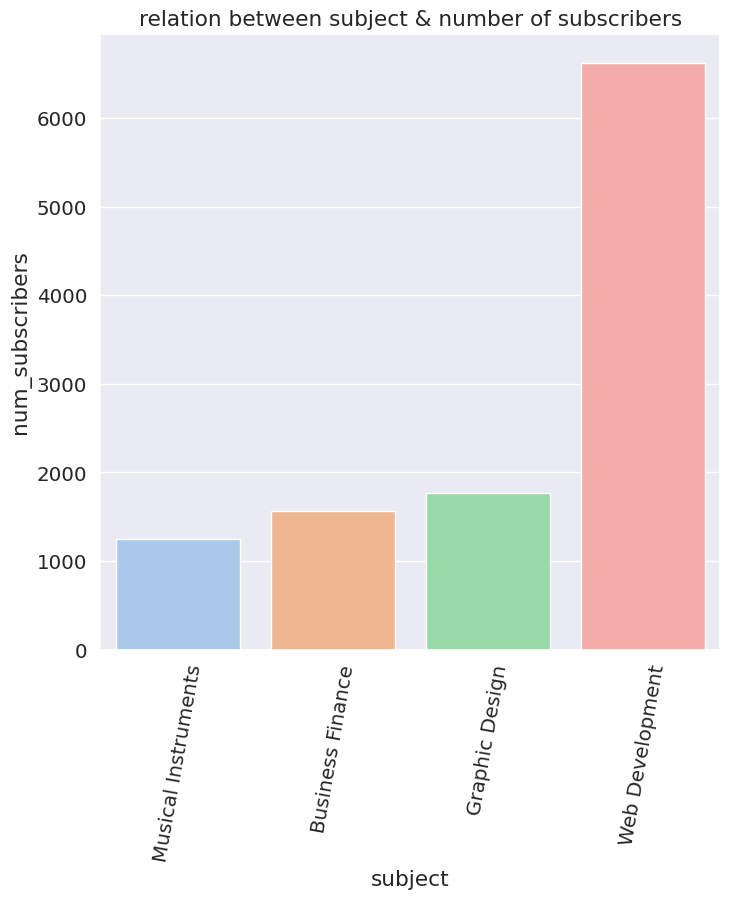

In [52]:
sns.barplot(data=df, x='subject', y='num_subscribers',errorbar=None,palette="pastel")
plt.title("relation between subject & number of subscribers")
plt.xticks(rotation = 80)
plt.show()

<Axes: xlabel='num_lectures', ylabel='num_reviews'>

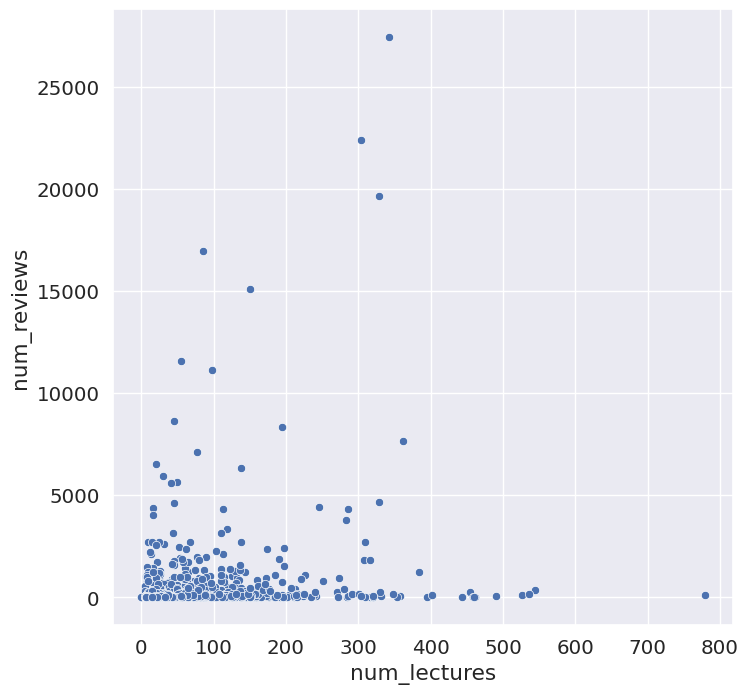

In [63]:
sns.scatterplot(data=df,x="num_lectures",y="num_reviews")

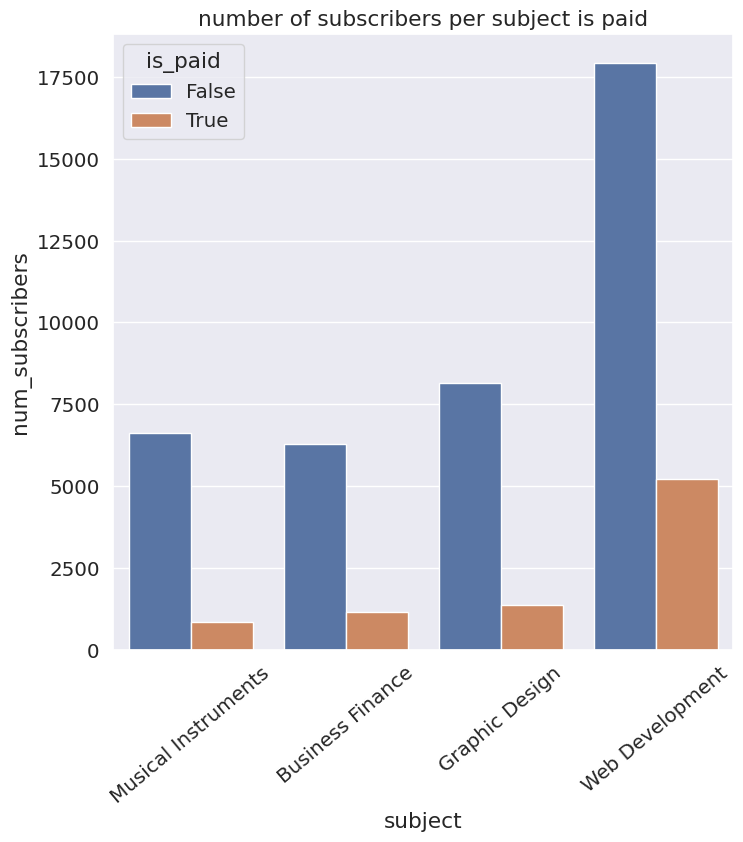

In [69]:
sns.barplot(data=df,x="subject",y="num_subscribers",hue="is_paid",errorbar=None)
plt.title("number of subscribers per subject is paid")
plt.xticks(rotation = 40)
plt.show()

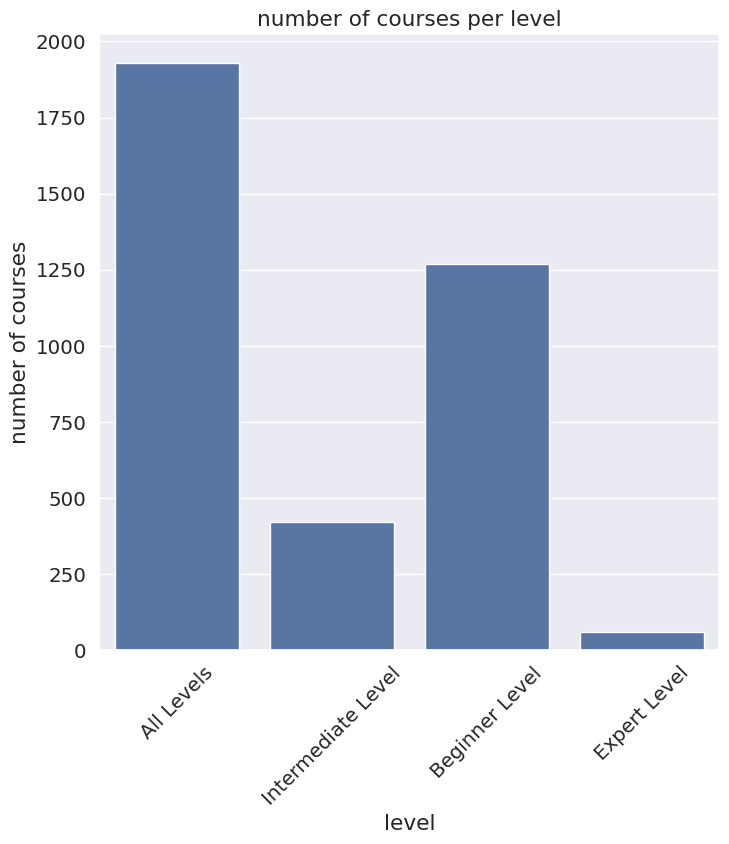

<Figure size 2000x800 with 0 Axes>

In [76]:
sns.countplot(data=df, x="level")
plt.title("number of courses per level")
plt.xlabel("level")
plt.ylabel("number of courses")
plt.xticks(rotation = 45)
plt.figure(figsize=(20,8))
plt.show()

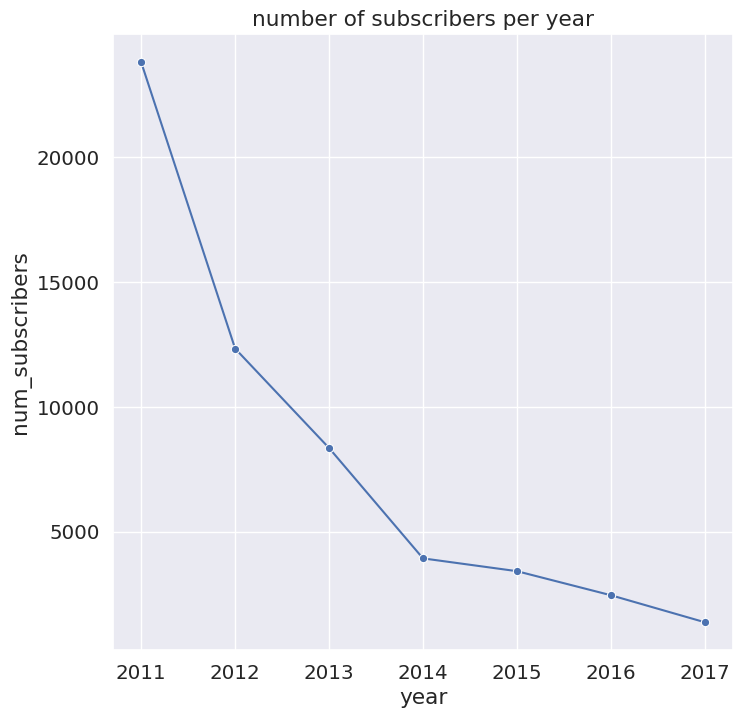

In [94]:
sns.lineplot(data=df,x="year",y="num_subscribers",marker="o",color="b" ,errorbar=None)
plt.title("number of subscribers per year")
plt.show()

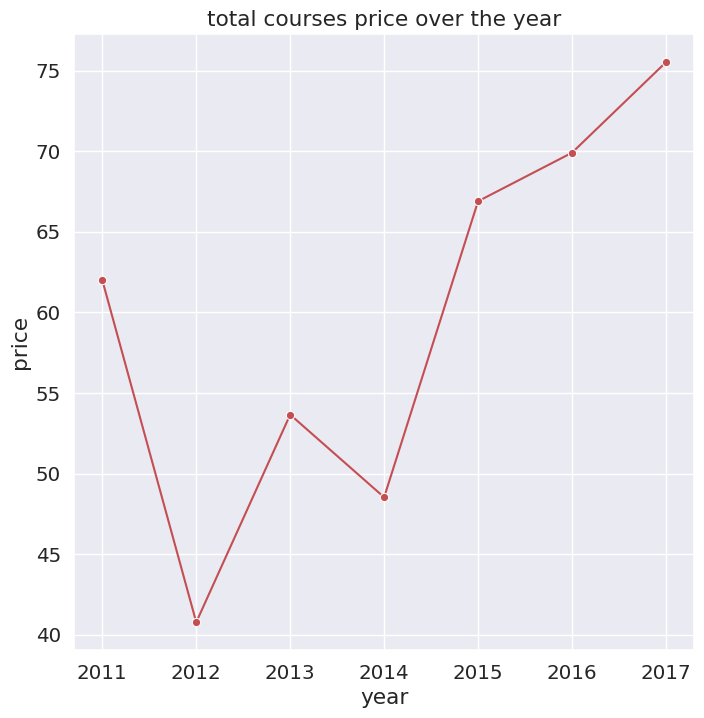

In [95]:
sns.lineplot(data=df,x="year",y="price",marker="o",color="r",errorbar=None)
plt.title("total courses price over the year")
plt.show()

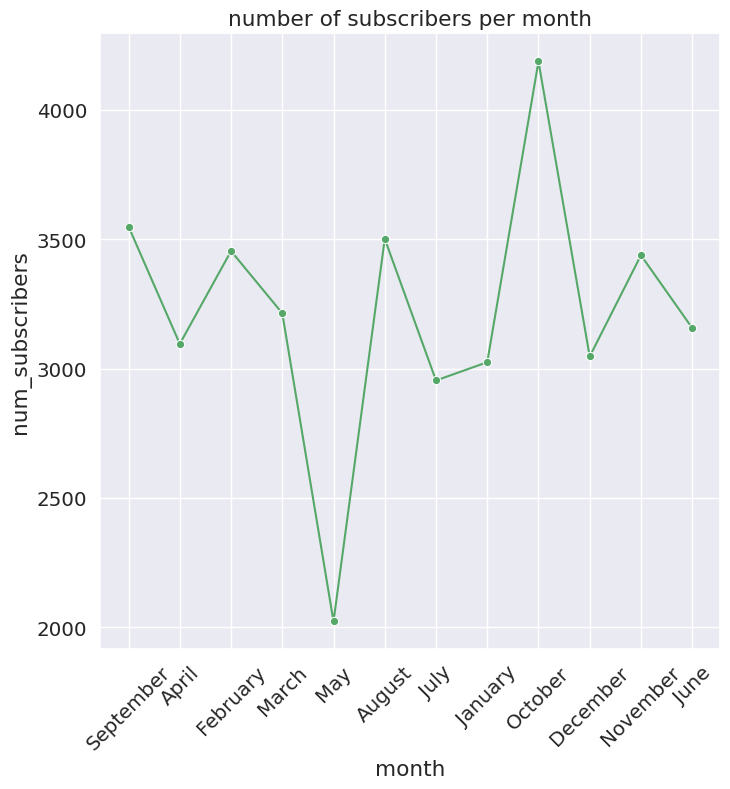

In [96]:
sns.lineplot(data=df,x="month",y="num_subscribers",marker="o",color="g",errorbar=None)
plt.title("number of subscribers per month")
plt.xticks(rotation= 45)
plt.show()

In [98]:
top_5 = df.nlargest(5, "num_subscribers")

top_5[["course_title", "num_subscribers"]]
top_5

,course_title,is_paid,price,num_subscribers,num_reviews,num_lectures,level,content_duration,subject,year,month
2230,Learn HTML5 Programming From Scratch,False,0,268923,8629,45,All Levels,10.5 hours,Web Development,2013,February
776,Coding for Entrepreneurs Basic,False,0,161029,279,27,Beginner Level,3.5 hours,Web Development,2013,June
3385,The Web Developer Bootcamp,True,200,121584,27445,342,All Levels,43 hours,Web Development,2015,November
640,Build Your First Website in 1 Week with HTML5 ...,False,0,120291,5924,30,Beginner Level,3 hours,Web Development,2014,April
3316,The Complete Web Developer Course 2.0,True,200,114512,22412,304,All Levels,30.5 hours,Web Development,2016,March


/tmp/ipykernel_932/2849239500.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_5,x="num_lectures",y="course_title",palette="coolwarm")


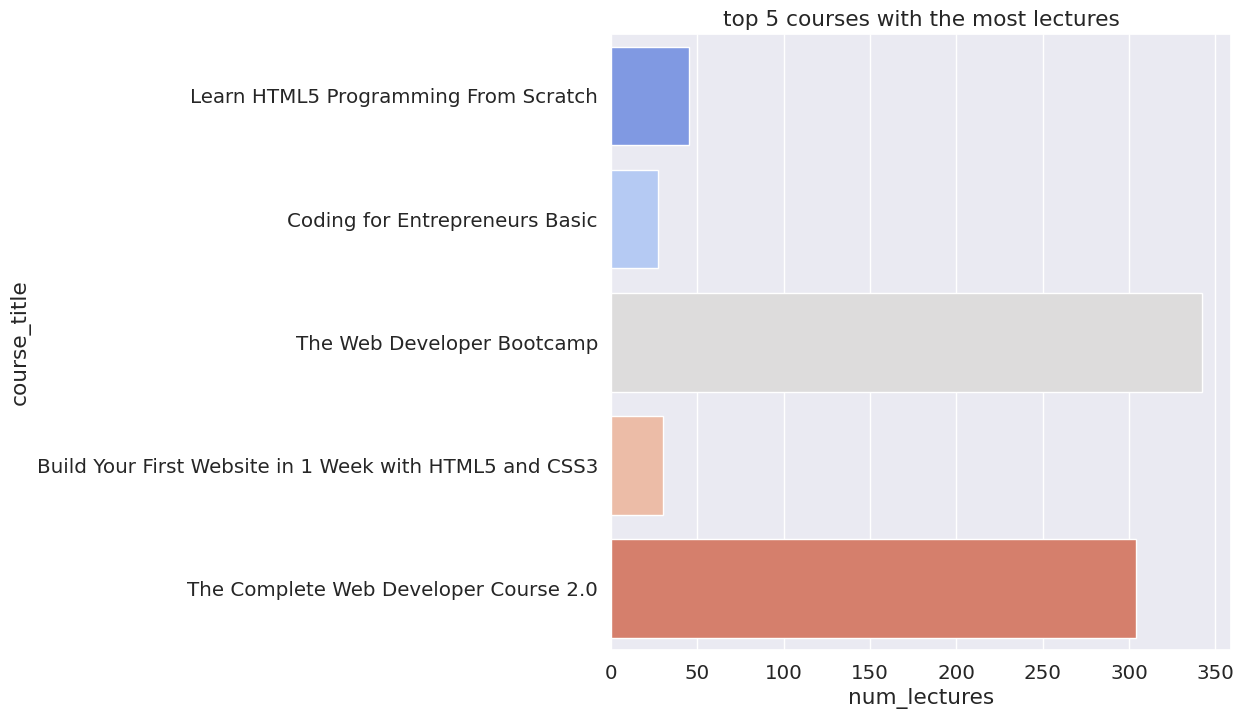

In [105]:
sns.barplot(data=top_5,x="num_lectures",y="course_title",palette="coolwarm")
plt.title("top 5 courses with the most lectures")
plt.show()

/tmp/ipykernel_932/2687285878.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_5,x="num_reviews",y="course_title",palette="magma")


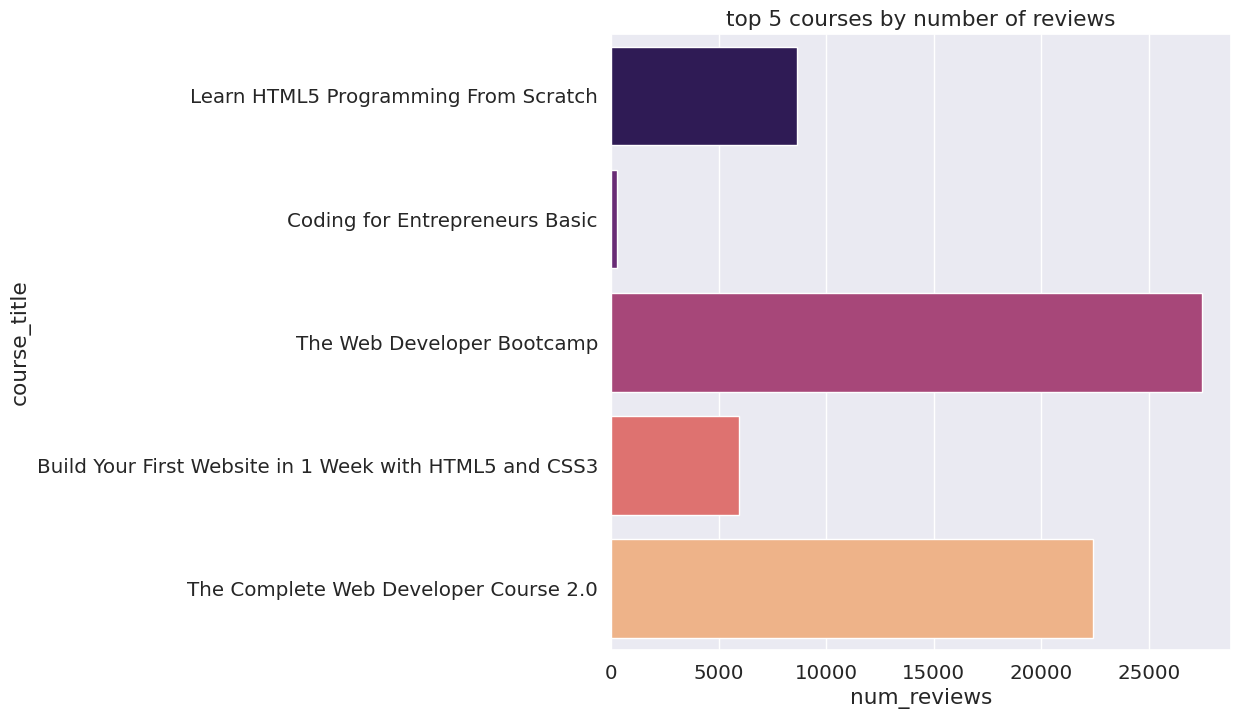

In [106]:
sns.barplot(data=top_5,x="num_reviews",y="course_title",palette="magma")
plt.title("top 5 courses by number of reviews")
plt.show()

/tmp/ipykernel_932/2692209775.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_5,x="num_subscribers",y="course_title",palette="pastel")


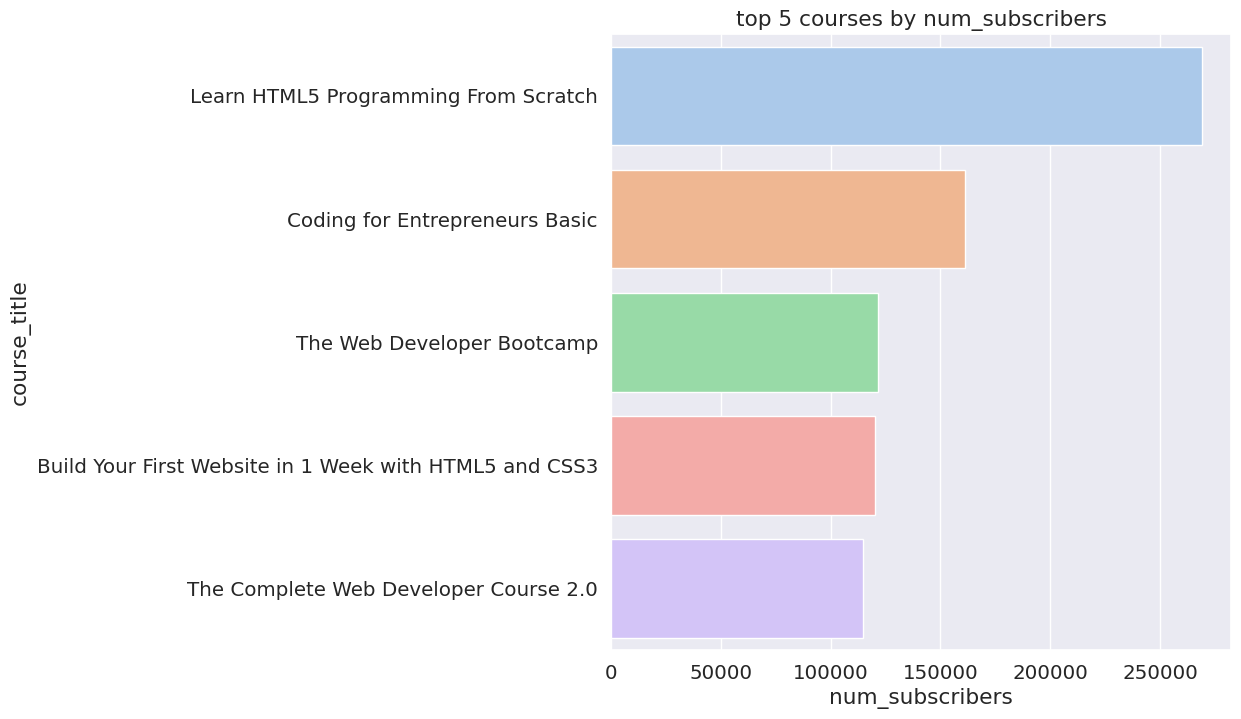

In [108]:
sns.barplot(data=top_5,x="num_subscribers",y="course_title",palette="pastel")
plt.title("top 5 courses by num_subscribers")
plt.show()